<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Housing_Pass_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Collection/Sources


### Load Modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

import requests

from google.colab import userdata
import os

### Authenticate to Hugging Face


In [3]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [5]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [6]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [7]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [8]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/housing_saleprice.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/housing_saleprice.parquet'

In [9]:
df3 = pd.read_parquet( hf_url )
df3.shape


(1984, 119)

In [10]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SalePrice       1984 non-null   int64  
 1   Overall Qual    1984 non-null   int64  
 2   Overall Cond    1984 non-null   int64  
 3   Bsmt Full Bath  1984 non-null   float64
 4   Bsmt Half Bath  1984 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 77.6 KB


In [11]:
X_features = df3.drop(columns=['SalePrice']).copy()
X_features

,Overall Qual,Overall Cond,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,...,Garage Type_BuiltIn,Garage Finish_RFn,Garage Finish_Unf,Garage Qual_Gd,Garage Qual_TA,Paved Drive_Y,Sale Type_ConLD,Sale Type_New,Sale Type_WD,Sale Condition_Partial
0,4,3,1.0,0.0,1,0,3,1,5,0,...,0,0,1,0,1,0,0,0,1,0
1,6,6,0.0,0.0,1,1,3,1,6,1,...,0,0,1,0,1,0,0,0,1,0
2,8,5,1.0,0.0,2,1,3,1,7,1,...,0,1,0,0,1,1,0,0,1,0
3,7,9,1.0,0.0,1,0,3,1,6,0,...,0,1,0,0,1,1,0,0,1,0
4,5,5,0.0,0.0,1,0,3,1,5,1,...,0,0,1,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,6,6,0.0,0.0,1,0,3,1,6,1,...,0,0,1,0,1,1,0,0,1,0
1980,7,6,1.0,0.0,1,1,1,1,4,0,...,0,0,1,0,1,1,0,0,1,0
1981,8,5,1.0,0.0,1,0,1,1,4,2,...,0,0,0,0,1,1,0,0,1,0
1982,6,5,0.0,0.0,2,0,3,1,7,1,...,0,1,0,0,1,1,0,0,1,0


In [12]:
y_target = df3['SalePrice'].copy()
y_target

,SalePrice
0,115400
1,141000
2,254000
3,155000
4,125000
...,...
1979,114500
1980,162000
1981,211500
1982,165000


# Backup

In [13]:
df = df3.copy()

# XGBoot Classification

In [15]:
numLoops = 10
rmspe_xgb = np.zeros(numLoops)

for idx in range(0, numLoops):
  X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.15)
  xgbr = xgb.XGBRegressor(objective='reg:squarederror', verbosity=0, seed=10, n_jobs=-1)
  xgbr.fit(X_train, y_train)
  y_pred_xgb = xgbr.predict(X_test)
  rmspe_xgb[idx] = np.sqrt(np.mean(((y_test - y_pred_xgb) / y_test) ** 2))

print(f'RMSPE: {rmspe_xgb.mean():.4f}')


RMSPE: 0.1811


## XGBoost with Parameters

In [16]:
# Specify the parameters you want to try and their ranges.
param_test = {
  'max_depth'     : [ 3, 4, 5, 6, 7 ],
  'learning_rate' : [ 0.1, 0.2, 0.3, 0.4 ],
  'n_estimators'  : [ 20, 40, 60, 80, 100, 120, 140 ],
}

# Perform the grid search
gsearch = GridSearchCV(
    estimator = xgb.XGBRegressor(objective='reg:squarederror', seed=10, n_jobs=-1),
    param_grid = param_test,
    scoring = 'neg_root_mean_squared_error',
    cv = 5,
)

# Fit to training data
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.05, random_state=42)
model = gsearch.fit(X_train, y_train)

# See grid search results
print(model.best_params_)

{'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 140}


Now we will fit our XGBoost model with the best parameters


In [17]:
params = model.best_params_

numLoops = 100
rmspe_xgb = np.zeros(numLoops)

for idx in range(0, numLoops):
  X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.15)
  xgbr = xgb.XGBRegressor(
      objective='reg:squarederror',
      verbosity=0,
      **params,
      seed=10,
      n_jobs=-1
  )
  xgbr.fit(X_train, y_train)
  y_pred_xgb = xgbr.predict(X_test)
  rmspe_xgb[idx] = np.sqrt(np.mean(((y_test - y_pred_xgb) / y_test) ** 2))

print(f'RMSPE: {rmspe_xgb.mean():.4f}')

RMSPE: 0.1785


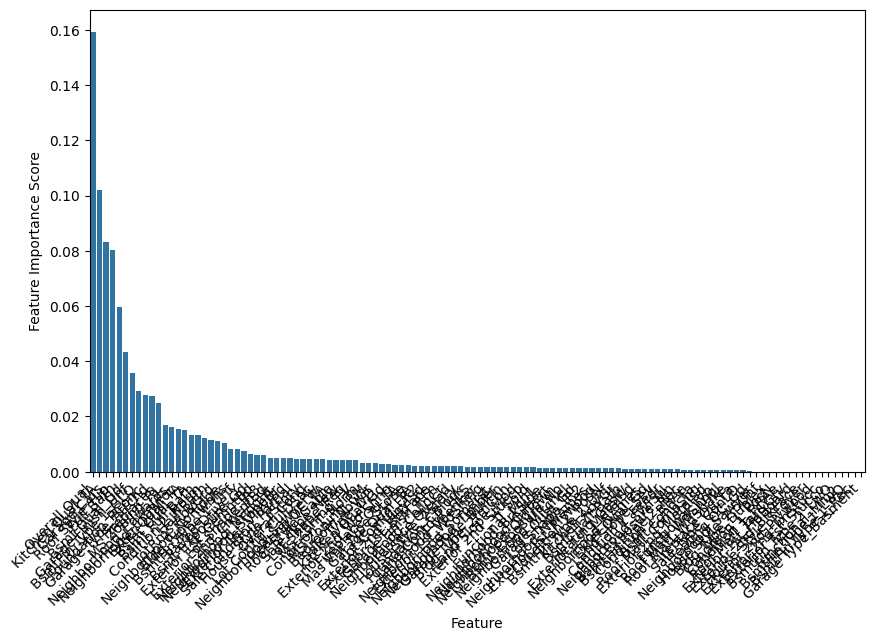

In [18]:
feat_imp = pd.Series(xgbr.feature_importances_, index=X_features.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.index, y=feat_imp.values)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Feature')
plt.ylabel('Feature Importance Score') ;

In [19]:
(feat_imp.sort_values( ascending = False )*100).cumsum()

,0
Overall Qual,15.936826
Kitchen Qual_TA,26.123121
Garage Cars,34.428192
Roof Style_Hip,42.465767
Full Bath,48.414352
...,...
BsmtFin Type 2_LwQ,100.000015
Functional_Min2,100.000015
BsmtFin Type 1_LwQ,100.000015
BsmtFin Type 1_Rec,100.000015
